In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
import numpy as np
from datetime import datetime
import seaborn as sns

In [35]:
random_state=2008
BASE='https://api.openf1.org/v1'

session_key=11253

driver_number=12


# Data functions

In [53]:
def get_sessions(year: int=2026, session_name=None) -> pd.DataFrame:

    params= {
        'year': year
    }
    if session_name is not None:
        params['session_name']=session_name

    races=requests.get(
        f'{BASE}/sessions',
        params=params,
    ).json()
    races=pd.DataFrame(races)

    races['date_start']=pd.to_datetime(races['date_start']).dt.tz_localize(None)
    races['date_end']=pd.to_datetime(races['date_end']).dt.tz_localize(None)

    return races

def get_drivers(session_key: int) -> pd.DataFrame:
    drivers=requests.get(
        f'{BASE}/drivers',
        params={
            'session_key':session_key,
        }
    ).json()

    drivers=pd.DataFrame(drivers)
    return drivers


def get_laps(session_key, driver_number=None):
    params={
        'session_key': session_key,
    }
    if driver_number is not None:
        params['driver_number']=driver_number


    laps = requests.get(
        f"{BASE}/laps",
        params=params,
    ).json()

    data= pd.DataFrame(laps)
    # data['date_start']=pd.to_datetime(data['date_start']).dt.tz_localize(None)
    return data


def get_telemetry(session_key, driver_number):
    telemetry = requests.get(
    f"{BASE}/car_data",
    params={
        "session_key": session_key,
        "driver_number": driver_number,
        },
    ).json()

    data= pd.DataFrame(telemetry)
    data['date'] = pd.to_datetime(data['date'], format='ISO8601').dt.tz_localize(None)
    return data


def get_car_data(session_key, driver_number):
    location = requests.get(
        f"{BASE}/location",
        params={
            "session_key": session_key,
            "driver_number": driver_number,
        },
    ).json()

    data = pd.DataFrame(location)
    data['date'] = pd.to_datetime(data['date'], format='ISO8601').dt.tz_localize(None)
    return data


def get_stints_data(session_key):
    tyres =requests.get(
        f'{BASE}/stints',
        params={
            'session_key': session_key
        }
    ).json()

    tyres_df=pd.DataFrame(tyres)
    return tyres_df


def get_weather_data(session_key):
    weather =requests.get(
        f'{BASE}/weather',
        params={
            'session_key': session_key
        }
    ).json()

    weather_df=pd.DataFrame(weather)
    weather_df['date']=pd.to_datetime(weather_df['date']).dt.tz_localize(None)
    return weather_df

# Data loading

In [37]:
races=get_sessions(year=2026, session_name='Race')
races.head()

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
0,11234,Race,Race,2026-03-08 04:00:00,2026-03-08 06:00:00,1279,10,Melbourne,5,AUS,Australia,Melbourne,11:00:00,2026,False
1,11245,Race,Race,2026-03-15 07:00:00,2026-03-15 09:00:00,1280,49,Shanghai,53,CHN,China,Shanghai,08:00:00,2026,False
2,11253,Race,Race,2026-03-29 05:00:00,2026-03-29 07:00:00,1281,46,Suzuka,4,JPN,Japan,Suzuka,09:00:00,2026,False
3,11261,Race,Race,2026-04-12 15:00:00,2026-04-12 17:00:00,1282,63,Sakhir,36,BRN,Bahrain,Sakhir,03:00:00,2026,True
4,11269,Race,Race,2026-04-19 17:00:00,2026-04-19 19:00:00,1283,149,Jeddah,153,KSA,Saudi Arabia,Jeddah,03:00:00,2026,True


In [38]:
drivers=get_drivers(session_key=session_key)
drivers.head()

,meeting_key,session_key,driver_number,broadcast_name,full_name,name_acronym,team_name,team_colour,first_name,last_name,headshot_url,country_code
0,1281,11253,1,L NORRIS,Lando NORRIS,NOR,McLaren,F47600,Lando,Norris,https://media.formula1.com/d_driver_fallback_i...,None
1,1281,11253,3,M VERSTAPPEN,Max VERSTAPPEN,VER,Red Bull Racing,4781D7,Max,Verstappen,https://media.formula1.com/d_driver_fallback_i...,None
2,1281,11253,5,G BORTOLETO,Gabriel BORTOLETO,BOR,Audi,F50537,Gabriel,Bortoleto,https://media.formula1.com/d_driver_fallback_i...,None
3,1281,11253,6,I HADJAR,Isack HADJAR,HAD,Red Bull Racing,4781D7,Isack,Hadjar,https://media.formula1.com/d_driver_fallback_i...,None
4,1281,11253,10,P GASLY,Pierre GASLY,GAS,Alpine,00A1E8,Pierre,Gasly,https://media.formula1.com/d_driver_fallback_i...,None


In [55]:
# laps=get_laps(session_key=session_key, driver_number=driver_number)
laps=get_laps(session_key=session_key)
laps.head()

,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1281,11253,12,1,2026-03-29T05:14:02.078000+00:00,38.853,42.420,17.942,285.0,332.0,False,99.215,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049]",293.0
1,1281,11253,63,1,2026-03-29T05:14:02.078000+00:00,37.965,42.185,18.120,287.0,330.0,False,98.270,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049]",291.0
2,1281,11253,81,1,2026-03-29T05:14:02.078000+00:00,35.660,41.939,18.112,280.0,313.0,False,95.711,"[2048, 2049, 2051, 2051, 2051, 2051, 2051, 205...","[2051, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2051, 2051, 2051, 2051]",279.0
3,1281,11253,16,1,2026-03-29T05:14:02.078000+00:00,36.900,41.648,18.305,267.0,320.0,False,96.853,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2051, 2049, 2049, 2049, 2049, 2049, 205...","[2049, 2049, 2049, 2049, 2049, 2049, 2049]",283.0
4,1281,11253,1,1,2026-03-29T05:14:02.078000+00:00,37.524,42.011,18.104,289.0,323.0,False,97.639,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2051, 2049, 2049, 2049, 204...","[2049, 2049, 2051, 2049, 2049, 2049, 2049]",283.0


In [41]:
telemetry=get_telemetry(session_key=session_key, driver_number=driver_number)
telemetry.head()

,date,session_key,rpm,drs,driver_number,meeting_key,speed,throttle,brake,n_gear
0,2026-03-28 07:03:24.451,11253,0,None,12,1281,0,0,0,0
1,2026-03-28 07:03:24.611,11253,0,None,12,1281,0,0,0,0
2,2026-03-28 07:03:24.931,11253,0,None,12,1281,0,0,0,0
3,2026-03-29 04:10:19.539,11253,4003,None,12,1281,0,0,0,0
4,2026-03-29 04:10:19.699,11253,4076,None,12,1281,0,0,0,0


In [42]:
position=get_car_data(session_key=session_key,driver_number=driver_number)
position.head()

,date,session_key,z,meeting_key,y,driver_number,x
0,2026-03-28 07:03:24.579,11253,830,1281,-848,12,1668
1,2026-03-28 07:03:24.799,11253,830,1281,-848,12,1668
2,2026-03-29 04:10:19.344,11253,0,1281,0,12,0
3,2026-03-29 04:10:19.604,11253,0,1281,0,12,0
4,2026-03-29 04:10:19.824,11253,0,1281,0,12,0


In [44]:
weather=get_weather_data(session_key=session_key)
weather.head()

,date,session_key,wind_direction,pressure,humidity,meeting_key,rainfall,air_temperature,wind_speed,track_temperature
0,2026-03-29 04:11:04.261,11253,115,1012.1,46.1,1281,0,19.4,3.1,37.0
1,2026-03-29 04:12:04.263,11253,140,1012.1,45.7,1281,0,19.4,1.9,38.0
2,2026-03-29 04:13:04.265,11253,124,1012.0,44.7,1281,0,19.4,3.3,37.3
3,2026-03-29 04:14:04.264,11253,126,1012.1,45.0,1281,0,19.5,2.3,37.7
4,2026-03-29 04:15:04.266,11253,118,1012.1,45.0,1281,0,19.5,2.5,37.4


In [45]:
stints=get_stints_data(session_key=session_key)
stints.head()

,meeting_key,session_key,stint_number,driver_number,lap_start,lap_end,compound,tyre_age_at_start
0,1281,11253,1,1,1,16,MEDIUM,0
1,1281,11253,1,87,1,16,MEDIUM,0
2,1281,11253,1,16,1,17,MEDIUM,0
3,1281,11253,1,43,1,17,MEDIUM,0
4,1281,11253,1,81,1,18,MEDIUM,0


# EDA

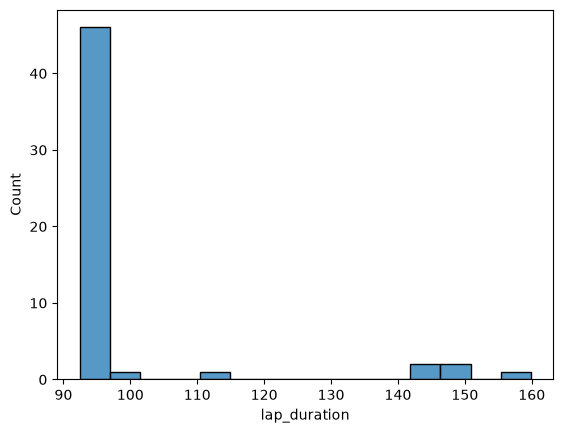

In [48]:
sns.histplot(laps['lap_duration'])
plt.show()

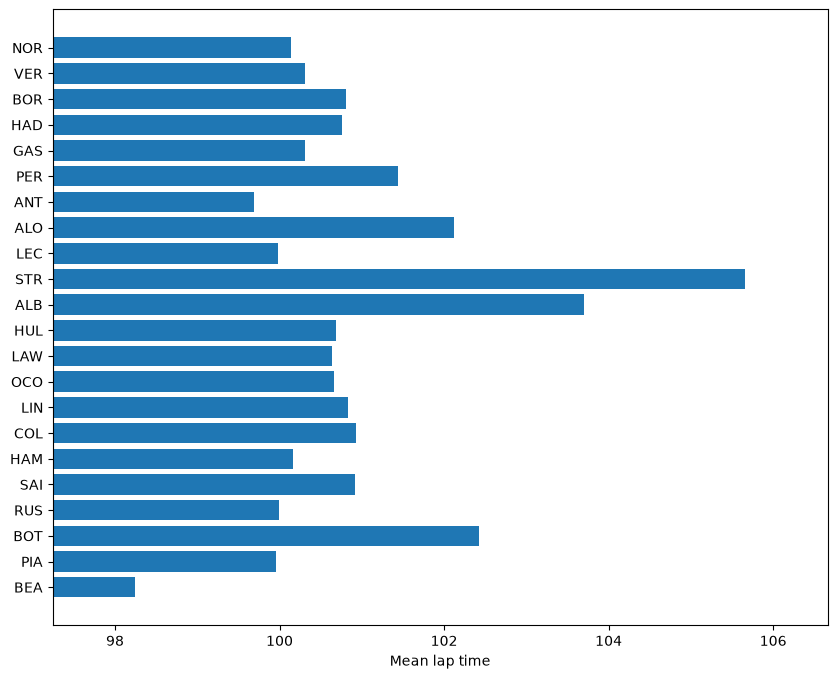

In [66]:
# Считаем pace каждого пилота

mean_lap_time=laps.groupby('driver_number', as_index=False).agg({'lap_duration': 'mean'})
mean_lap_time_with_acronyms=pd.merge(mean_lap_time, drivers[['driver_number', 'name_acronym']])

plt.figure(figsize=(10, 8))

plt.barh(mean_lap_time_with_acronyms['name_acronym'],mean_lap_time_with_acronyms['lap_duration'])
plt.xlim(mean_lap_time_with_acronyms['lap_duration'].min()-1, mean_lap_time_with_acronyms['lap_duration'].max()+1)

plt.gca().invert_yaxis()

plt.xlabel('Mean lap time')
plt.show()

In [ ]:
for dn in laps['driver_number'].unique():
    data=laps[laps['driver_number']==dn]
    plt.plot(data[''])